Objetivo: Entrenar un modelo neuronal con capas lineales (MLP) para que aprenda a reconstruir una imagen (el dibujo de Shin Chan)1.Resolución de trabajo: Para simplificar la práctica, la imagen se reducirá inicialmente a un tamaño de $35 \times 30$ píxeles1.Concepto: Una imagen son colores asociados a una posición $(x, y) \longrightarrow (R, G, B)$2. El modelo debe reproducir la imagen sin necesitar el archivo original una vez entrenado2.Codificación Posicional (Positional Encoding): Como los MLPs tienen dificultades para aprender cambios bruscos de color (variaciones de alta frecuencia), se debe transformar la entrada $(x, y)$ usando funciones trigonométricas (seno y coseno) a distintas frecuencias mediante la clase Positional_Encoder (con $L=10$ y include_input=True)2more_horiz.Upscaling: Una vez entrenado el MLP, se requiere utilizarlo para generar la imagen al doble de resolución ($70 \times 60$)4.

In [1]:
import math
import torch
import torch.nn as nn


class Positional_Encoder(nn.Module):
    def __init__(self, L=10, include_input=True, device='cpu'):
        super(Positional_Encoder, self).__init__()
        self.include_input = include_input
        self.device = device
        self.freq_bands = 2.0 ** torch.linspace(0.0, L - 1, L, device=self.device)

    def forward(self, x):
        out = [x] if self.include_input else []
        for freq in self.freq_bands:
            out.append(torch.sin(freq * x * math.pi))
            out.append(torch.cos(freq * x * math.pi))
        return torch.cat(out, dim=-1)

    def get_output_dim(self, input_dim):
        return (input_dim if self.include_input else 0) + 2 * input_dim * len(self.freq_bands)

Tensor Image shape: torch.Size([3, 30, 35])
Colors shape: torch.Size([1050, 3])
Tamaño coordenadas: torch.Size([1050, 2])


(np.float64(-0.5), np.float64(34.5), np.float64(29.5), np.float64(-0.5))

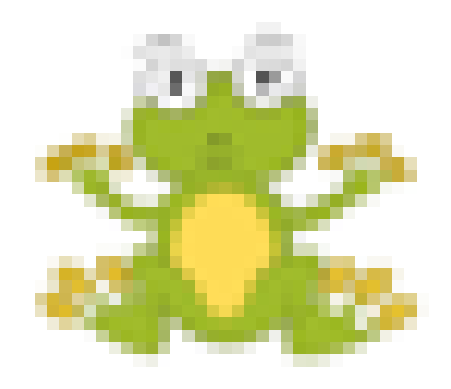

In [ ]:
from PIL import Image
import torch
from torchvision import transforms
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt

width, heigh = 35, 30
image = Image.open("frog_png.jpg").convert("RGB")
image = image.resize((width, heigh))

transform = transforms.ToTensor()
image = transform(image)
print(f"Tensor Image shape: {image.shape}")

colors = image.permute(1, 2, 0).reshape(-1, 3)
print(f"Colors shape: {colors.shape}")

x = torch.linspace(0, 1, steps=width)
y = torch.linspace(0, 1, steps=heigh)

grid_x, grid_y = torch.meshgrid(y, x, indexing='ij')
coordinates = torch.stack([grid_x.flatten(), grid_y.flatten()], dim=1)

print(f"Tamaño coordenadas: {coordinates.shape}")

plt.imshow(image.permute(1, 2, 0)) # Lo permuto porque es un tensor de la imagen.
plt.axis("off")

In [6]:
dataset = TensorDataset(coordinates, colors)
dataloader = DataLoader(dataset, batch_size=256, shuffle=True)

In [7]:
class ImageMLP(nn.Module):
    def __init__(self):
        super().__init__()

        self.encoder = Positional_Encoder(L=10, include_input=True)

        dim_input = self.encoder.get_output_dim(input_dim=2)

        self.entrance = nn.Linear(dim_input, 256)

        self.layer_one = nn.Linear(256, 256)

        self.layer_two = nn.Linear(256, 256)

        self.output = nn.Linear(256, 3)

    def forward(self, x):
        x = self.encoder(x)
        x = torch.relu(self.entrance(x))
        x = torch.relu(self.layer_one(x))
        x = torch.relu(self.layer_two(x))
        x = torch.relu(self.output(x))
        x = torch.sigmoid(x)
        return x

In [ ]:
device = torch.device("cuda")
model = ImageMLP().to(device)

loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr = 0.001)

epochs = 1000
loss_history = []

for epoch in range(epochs):
    model.train()
    